# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 1: Reconstrucción de una imagen

**Grupo:** 2

**Integrantes:**
- Alondra Estay Alcayaga
- Gapar Galaz Wood
- José Mora Gatica
- Renato Reyes Roa

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). En este problema, excepcionalmente, pueden usar `np.linalg.solve` en (b), (c) y (d).
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)

## Datos

El archivo `datos_P1.npz` debe estar en la misma carpeta que este notebook.

In [26]:
datos = np.load("datos_P1.npz")
A = datos["A"]          # matriz de desenfoque (n x n)
b = datos["b"]          # imagen observada
b_def = datos["b_def"]  # imagen observada con píxeles dañados, para (d)

n = b.size
N = int(np.sqrt(n))
sigma = 0.01
delta = sigma * np.sqrt(n)
print(f"A: {A.shape},  b: {b.shape},  b_def: {b_def.shape},  N = {N},  delta = {delta:.2f}")

A: (4096, 4096),  b: (4096,),  b_def: (4096,),  N = 64,  delta = 0.64


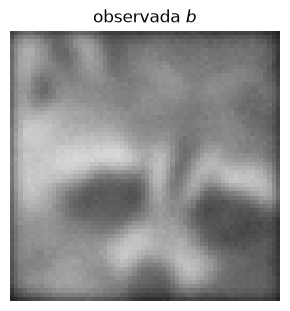

In [27]:
def mostrar(imagenes, titulos, archivo=None):
    """Muestra vectores de largo n como imágenes de N x N, lado a lado (valores fuera de [0, 1] se recortan)."""
    fig, axs = plt.subplots(1, len(imagenes), figsize=(3 * len(imagenes), 3.2))
    axs = np.atleast_1d(axs)
    for ax, v, t in zip(axs, imagenes, titulos):
        ax.imshow(v.reshape(N, N), cmap="gray", vmin=0, vmax=1)
        ax.set_title(t)
        ax.axis("off")
    fig.tight_layout()
    if archivo is not None:
        fig.savefig(os.path.join("figuras", archivo), dpi=200, bbox_inches="tight")
    plt.show()


mostrar([b], ["observada $b$"], archivo="ejemplo_b.png")

## (a) Mínimos cuadrados
Consideraremos la función:
$$
J_0(x)=\|Ax-b\|_2^2
$$

### i. Cálculo del Gradiente y Matriz Hessiana de $J_0$

##### • Cálculo del gradiente

Para calcular el gradiente, primero expandiremos la función utilizando la propiedad de la norma euclidiana al cuadrado, $\|x\|_2^2=x^Tx$:

$$
\begin{aligned}
J_0(x) &= (Ax-b)^T(Ax-b)\\
&=x^TA^TAx-x^TA^Tb-b^TAx+b^Tb\\
\end{aligned}
$$

Como $x^TA^Tb$ es un escalar, es igual a su transpuesta, es decir:

$$
x^TA^Tb=(x^TA^Tb)^T=b^TAx
$$ 

Al tener esto en consideración, podemos agrupar los términos del medio y obtener:

$$
J_0(x)=x^TA^TAx-2x^TA^Tb+b^Tb
$$

Con la función expresada de esta forma, podemos calcular su gradiente derivando cada término respecto del vector $x$.
Realizando la derivación, obtenemos que la gradiente de $J_0$ es:

$$
\boxed{\nabla J_0(x)=2A^T(Ax-b)}
$$

##### • Cálculo Matriz Hessiana

Para calcular la matriz Hessiana, debemos encontrar las segundas derivadas parciales de una función. En este caso, como $J_0(x)$ depende del vector $x$, podemos obtener la Hessiana derivando el gradiente respecto de $x$ (asumiendo que las matricres $A$ y $A^T$ y el vector $b$ son constantes)

Por lo tanto, la matriz Hessiana es:

$$
\boxed{H_{J_0}=2A^TA}
$$


##### • Deducción de las ecuaciones normales

Para demostrar que los puntos críticos de $J_0(x)$ corresponden a las soluciones de las ecuaciones normales, debemos recordar que un punto crítico de una función es aquel donde su gradiente es igual a cero. Por lo que, utilizaremos el gradiente obtenido anteriormente y lo igualamos a cero:

$$
\nabla J_0(x)=2A^T(Ax-b)=0
$$

Simplificamos dividiendo por $2$ y distribuimos la matriz $A^T$:

$$
\begin{aligned}
A^T(Ax-b)&=0\\
A^TAx-A^Tb&=0\\
A^TAx&=A^Tb
\end{aligned}
$$

De esta manera, obtenemos la expresión para las ecuaciones normales:

$$
\boxed{A^TAx=A^Tb}
$$

Por lo tanto, concluimo que si un vector $x$ es un punto crítico de $J_0(x)$, entonces necesariamente satisface las ecuaciones normales.


### ii. Hessiana semidefinida positiva y mínimos globales

##### • Demostración Hessiana semidefinida positiva

Para demostrar que una matriz $H$ sea semidefinida positiva, se debe cumplir que $v^THv\geq 0$ para cualquier vector $v\in\mathbb{R}^n$

Del ítem i, obtuvimos que la matriz Hessiana es:

$$
H_{J_0}=2A^TA
$$

Dado que $H_{J_0}$ es simétrica ya que, $(2A^TA)^T=2A^TA$, evaluamos la condición anterior tomando un vector cualquiera $v\in\mathbb{R}^n$ y reemplazamos los valores:

$$
\begin{aligned}
v^TH_{J_0}v
&=v^T(2A^TA)v\\
&=2v^TA^TAv\\
&=2(Av)^T(Av)\\
&=2\|Av\|_2^2.
\end{aligned}
$$

Sabemos que una norma al cuadrado siempre es mayor o igual a cero. Por lo tanto:

$$
\boxed{v^TH_{J_0}v=2\|Av\|_2^2\geq 0}
$$

Como esta desigualdad se cumple para cualquier vector $v$, concluimos que la matriz Hessiana $H_{J_0}$ es semidefinida positiva.

##### • Demostración de que todo punto crítico es un mínimo global

Para demostrar que cualquier punto crítico de $J_0(x)$ es un mínimo global, utilizaremos la aproximación de Taylor de segundo orden. Al ser $J_0(x)$ una función cuadrática, esta aproximación es exacta y podemos expresarla como:

$$
J_0(x)=J_0(x_0)+\nabla J_0(x_0)^T(x-x_0)+\frac{1}{2}(x-x_0)^TH_{J_0}(x-x_0)
$$

Considerando $x_0$ un punto crítico, sabemos que su gradiente es igual a cero, es decir, $\nabla J_0(x_0)=0$. Teniendo esto en cuenta, podemos simplificar la expresión, obteniendo:

$$
J_0(x)=J_0(x_0)+\frac{1}{2}(x-x_0)^TH_{J_0}(x-x_0)
$$

Además, como demostramos anteriormente que la matriz Hessiana es semidefinida positiva, el término cuadrático es siempre mayor o igual a cero.

$$
\frac{1}{2}(x-x_0)^TH_{J_0}(x-x_0)\geq 0
$$

De esta manera, obtenemos:

$$
\boxed{J_0(x)\geq J_0(x_0)}
$$

Con esto podemos deducir que el valor de la función en cualquier punto $x$ es mayor o igual que su valor en el punto crítico $x_0$. Por lo tanto, concluimos que todo punto crítico de $J_0(x)$ es un mínimo global de la función.
<br>
<br>

### iii. Minimizadores

##### • Todos los valores propios de $A^TA$ son positivos

Si todos los valores propios de $A^TA$ son positivos, entonces esta matriz es definida positiva y, por lo tanto, invertible. 

Del ítem i, sabemos que todos los puntos críticos de $J_0(x)$ satisfacen las ecuaciones normales:

$$
A^TAx=A^Tb
$$

Como $A^TA$ es invertible, multiplicamos ambos lados por su inversa para despejar $x$:

$$
\boxed{x=(A^TA)^{-1}A^Tb}
$$

Por lo tanto, las ecuaciones normales tienen una única solución, la cual corresponde a un mínimo global de $J_0(x)$, según lo demostrado en el ítem ii. Con esto podemos concluir que, cuando todos los valores propios de $A^TA$ son positivos, la función $J_0(x)$ tiene un único minimizador global.
<br>
<br>

##### • $A^TA$ tiene al menos un valor propio nulo

Si $A^TA$ tiene un valor propio igual a cero, entonces existe un vector $v\neq 0$ tal que $A^TAv=0$.

Multiplicando por $v^T$ y utilizando la propiedad de la norma euclidiana, obtenemos:

$$
v^TA^TAv=\|Av\|_2^2=0
$$

Como una norma solo es cero cuando el vector es nulo, concluimos que $Av=0$.

Para demostrar que existen infinitos minimizadores, consideramos un punto crítico $x_0$ de $J_0(x)$, que por lo demostrado en el ítem ii también es un mínimo global. A partir de este punto, podemos construir nuevos vectores de la forma $x_t=x_0+tv$, con $t\in\mathbb{R}$. Para comprobar si estos también son minimizadores, los reemplazamos en la función:

$$
\begin{aligned}
J_0(x_t)
&=\|A(x_0+tv)-b\|_2^2\\
&=\|Ax_0+tAv-b\|_2^2\\
&=\|Ax_0-b\|_2^2\\
&=J_0(x_0)
\end{aligned}
$$

Como $Av=0$, todos los vectores $x_t$ entregan el mismo valor de la función que $x_0$, por lo que también son mínimos globales. Además, como $v\neq 0$ y $t$ puede tomar infinitos valores, podemos generar infinitos vectores distintos. Por lo tanto, concluimos que, si $A^TA$ tiene al menos un valor propio nulo, la función $J_0(x)$ tiene infinitos minimizadores globales.

## (b) Reconstrucción

### i. Implementación

In [ ]:
x0 = np.linalg.solve(A, b)
norma_x0 = np.linalg.norm(x0)
max_x0 = np.max(np.abs(x0))
residuo_x0 = np.linalg.norm(np.dot(A, x0) - b)


Norma de x0: 350302.17800191656
Máximo absoluto de x0: 18711.633354553953
Residuo: 5.625585081989651e-12


### ii. Explicación

## (c) Regularización de Tikhonov

### iv. Implementación

In [29]:
# TODO

## (d) Píxeles dañados

In [30]:
# TODO

### ii. $\|\tilde{b} - b\|_2$

In [31]:
# TODO

## (Bonus) Mínimos cuadrados ponderados

In [32]:
# TODO